In [1]:
import os

# Byter arbetskatalog från notebooks till projektroten, så att Python kan hitta både src/ och data/
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Kontrollerar vilken mapp Python arbetar från
print(os.getcwd())

c:\Users\Speldator\Desktop\data-science-group-project


In [2]:
from src.data_split import load_cleaned_data, get_splits

# Läser in den rensade datan från data/processed/
df = load_cleaned_data()

# Kontrollerar datasetets storlek
print("Antal bokningar:", df.shape[0])
print("Antal kolumner:", df.shape[1])

# Visar fem slumpmässiga bokningar
df.sample(5, random_state=42).T

2026-10-13 14:52:50 [INFO] src.data_split: Läser in städad data från data\processed\hotel_bookings_cleaned.csv
Antal bokningar: 110428
Antal kolumner: 34


,2448,48466,13766,20972,80486
hotel,Resort Hotel,City Hotel,Resort Hotel,Resort Hotel,City Hotel
is_canceled,1,1,0,0,0
lead_time,112,179,73,21,82
arrival_date_year,2016,2016,2015,2016,2016
arrival_date_month,February,July,September,June,May
arrival_date_week_number,7,27,40,23,21
arrival_date_day_of_month,12,1,28,2,17
stays_in_weekend_nights,0,0,1,0,0
stays_in_week_nights,2,2,1,1,3
adults,2,2,2,1,3


In [3]:
# Delar upp den rensade datan kronologiskt
splits = get_splits(df)

# Hämtar träningsdata och valideringsdata
train = splits["train_val"]
val = splits["val"]

# Kontrollerar antal rader och kolumner
print("Train:", train.shape)
print("Validation:", val.shape)

2026-10-13 14:52:51 [INFO] src.data_split: Split vid 2016-07-01: 40414 träning (avbokade 0.308), 11643 utvärdering (avbokade 0.353)
2026-10-13 14:52:51 [INFO] src.data_split: Split vid 2016-10-01: 55393 träning (avbokade 0.321), 14879 utvärdering (avbokade 0.396)
Train: (40414, 34)
Validation: (11643, 34)


In [4]:
from src.preprocessing import split_features_target

# Separera features (X) och facit (y) för träningsdatan
X_train, y_train = split_features_target(train)

# Gör samma sak för valideringsdatan
X_val, y_val = split_features_target(val)

# Kontrollera dimensionerna
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (40414, 12)
y_train: (40414,)
X_val: (11643, 12)
y_val: (11643,)


In [5]:
from src.preprocessing import build_preprocessor

# Skapar preprocessorn med gruppens gemensamma inställningar
preprocessor = build_preprocessor()

# Lär sig medelvärden, standardavvikelser och kategorier från träningsdatan och omvandlar sedan denna
X_train_processed = preprocessor.fit_transform(X_train)

# Omvandlar valideringsdatan med samma inställningar
# Ingen ny fit() görs, vilket förhindrar dataläckage
X_val_processed = preprocessor.transform(X_val)

# Kontrollerar dimensionerna efter preprocessing
print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)

Train: (40414, 466)
Validation: (11643, 466)


In [6]:
from src.logistic_regression import train_logistic_regression

# Tränar Logistic Regression på den förbehandlade träningsdatan
model = train_logistic_regression(
    X_train_processed,
    y_train
)

# Bekräftar att modellen har tränats
print("Logistic Regression är tränad!")

Logistic Regression är tränad!


In [7]:
from src.logistic_regression import predict_probabilities

# Beräknar sannolikheten för avbokning (klass 1)
# för varje bokning i valideringsdatan
probabilities = predict_probabilities(
    model,
    X_val_processed
)

# Visar de första 10 sannolikheterna
print(probabilities[:10])

[0.09188294 0.05981597 0.10951735 0.07325343 0.10626286 0.07117
 0.07554162 0.28070491 0.16905574 0.06886754]


In [8]:
from src.logistic_regression import predict_with_threshold

# Väljer gränsen för när en bokning klassificeras som avbokad
threshold = 0.2

# Omvandlar sannolikheterna till klass 0 eller 1
y_pred = predict_with_threshold(
    probabilities,
    threshold=threshold
)

# Visar de första 10 förutsägelserna
print(y_pred[:10])

[0 0 0 0 0 0 0 1 0 0]


In [9]:
from src.evaluation import evaluate_model

# Jämför modellens förutsägelser med facit
results = evaluate_model(y_val, y_pred)

# Skriver ut Precision, Recall och F1-score i procent
for metric, value in results.items():
    print(f"{metric}: {value:.2%}")

Precision: 44.08%
Recall: 83.20%
F1-score: 57.63%


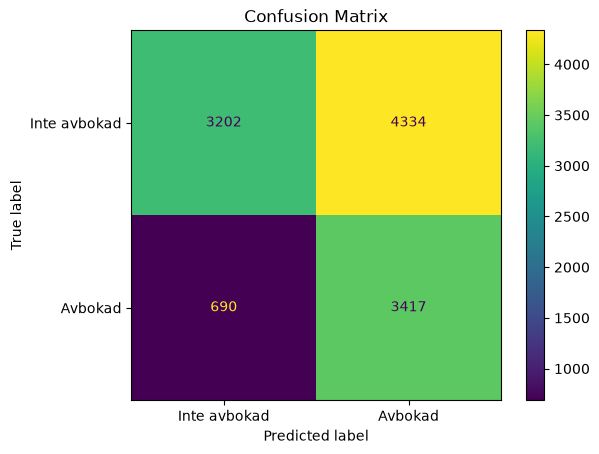

In [10]:
from src.evaluation import plot_confusion_matrix

# Visualiserar modellens förutsägelser mot facit
# y_val = verkliga utfall
# y_pred = modellens förutsägelser med threshold 0.50
plot_confusion_matrix(y_val, y_pred)

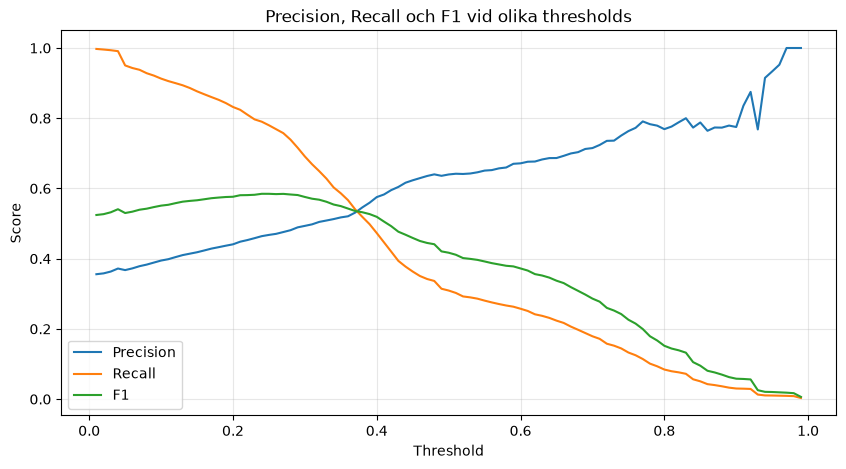

In [11]:
from src.evaluation import plot_threshold_metrics

# Visar hur Precision, Recall och F1 förändras när threshold varierar mellan 0.01 och 0.99.
plot_threshold_metrics(y_val, probabilities)

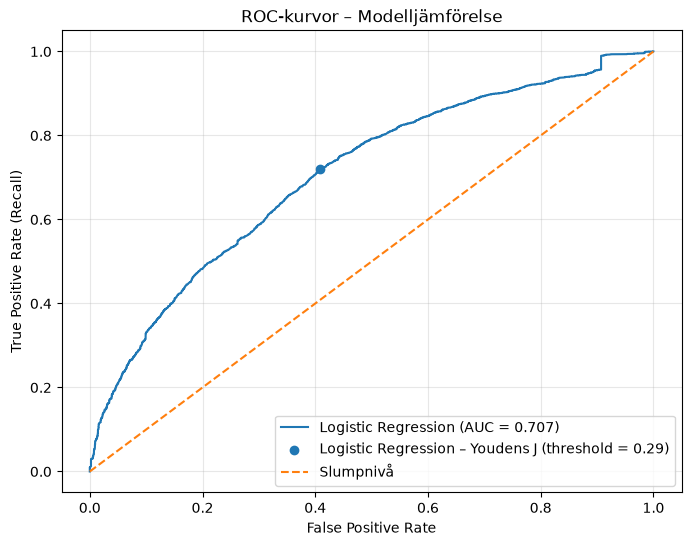

In [12]:
from src.evaluation import plot_roc_curve


# Skapar en dictionary med modellnamn och sannolikheter.
predictions = {
    "Logistic Regression": probabilities
}

# Ritar ROC-kurvan.
roc_results = plot_roc_curve(y_val, predictions)

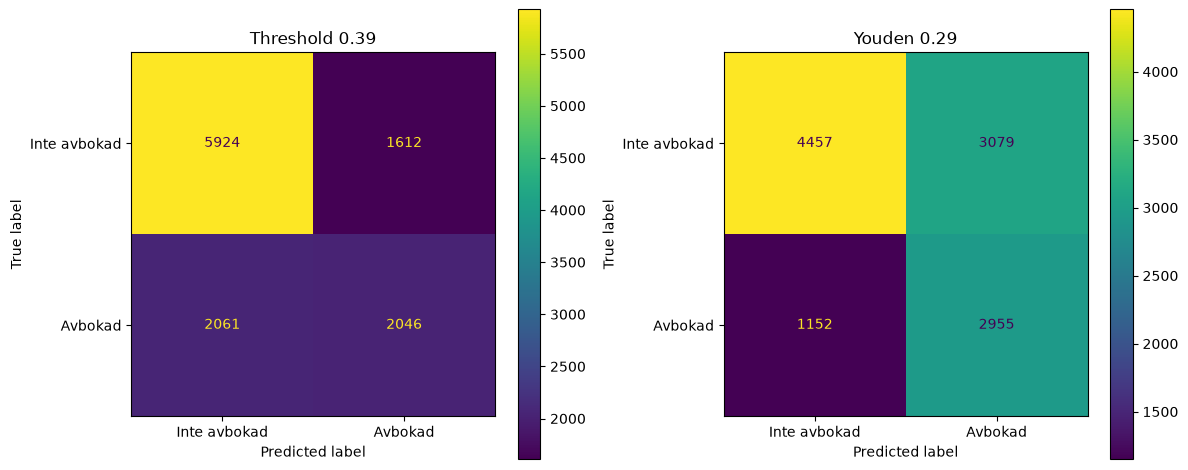

In [14]:
from src.evaluation import plot_multiple_confusion_matrices

# Jämför Confusion Matrix för två olika thresholds.
predictions = {
    "Threshold 0.39": predict_with_threshold(
        probabilities, 0.39
    ),
    "Youden 0.29": predict_with_threshold(
        probabilities,
        roc_results["Logistic Regression"]["youden_threshold"]
    )
}

plot_multiple_confusion_matrices(y_val, predictions)

In [15]:
# Hämtar förutsägelserna med Youdens threshold
y_pred_youden = predictions["Youden 0.29"]

# Beräknar Precision, Recall och F1
results_youden = evaluate_model(y_val, y_pred_youden)

for metric, value in results_youden.items():
    print(f"{metric}: {value:.2%}")

Precision: 48.97%
Recall: 71.95%
F1-score: 58.28%
